# Gamblers and Large Numbers

Here's a [question from the Reddit statistics forum](https://www.reddit.com/r/AskStatistics/comments/1b0332n/comment/ks5gys0).

>  Law of truly large numbers and gambler's fallacy: I keep feeling the two conflict each other. Can someone help me get an intuitive understanding of the difference?
>
> I've learned that if you are tossing a coin and wanting to bet on getting a tail, but instead get one hundred heads in a row, you should not double your bet that the 101st one is going to be a tail because the chance is still 1/2, assuming a fair coin. In other words, the sequence has no memory, and every toss is independent of the previous, and to think otherwise is the Gambler's Fallacy.
>
> Yet, when I was reading about the Law of Large Numbers [...], it seemed the idea is that with enough repetitions of independent events, the average is expected to be closer to the expected value. With the coin toss, I imagine that means we are going to get a fairly similar number of heads and tails, given the expected value of 1/2 for a fair coin.
>
> I keep thinking that it conflicts with the above. Where is my misunderstanding? Thanks for your help.

Both of these claims are correct:

* If a coin is known to be fair, the probability of heads is always 1/2, regardless of the outcome of all previous tosses.

* Nevertheless, even if you start by throwing 100 consecutive heads, if you toss enough coins, the proportion of heads will tend to converge toward 1/2.

It might seem like there's a contradiction there -- if the sequence has no memory, why should the proportion converge back to 1/2?
Let's see if we can resolve it.

[Click here to run this notebook on Colab](https://colab.research.google.com/github/AllenDowney/DataQnA/blob/main/nb/gambler.ipynb).

I'll download a utilities module with some of my frequently-used functions, and then import the usual libraries.

In [1]:
from os.path import basename, exists

def download(url):
    filename = basename(url)
    if not exists(filename):
        from urllib.request import urlretrieve

        local, _ = urlretrieve(url, filename)
        print("Downloaded " + str(local))
    return filename

download('https://github.com/AllenDowney/DataQnA/raw/main/nb/utils.py');

In [2]:
# install the empiricaldist library, if necessary

try:
    import empiricaldist
except ImportError:
    !pip install empiricaldist

In [3]:
import numpy as np
np.set_printoptions(legacy='1.25')
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from utils import decorate

## Flip Flop

To see what's going on, it will help to be more precise about the second point.
After tossing 100 heads in a row, what do we expect to see next, and what do we expect to see in the long run?

I'll represent the outcomes as an array of strings, starting with 100 heads.

In [4]:
prefix = np.full(100, 'H')

Now suppose the coin is fair and we toss it 5000 more times.

In [5]:
np.random.seed(17)
n = 5000
flips = np.random.choice(['H', 'T'], size=n)
sequence = np.concatenate([prefix, flips])

Here's the cumulative number of heads after each toss.

In [6]:
num_heads = (sequence == 'H').cumsum()
ns = np.arange(1, len(sequence) + 1)

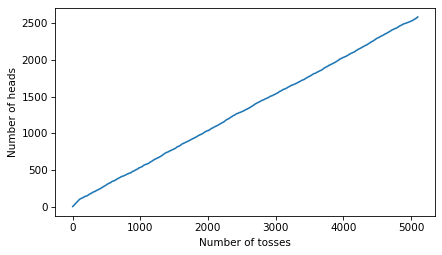

In [7]:
plt.plot(ns, num_heads)
decorate(xlabel='Number of tosses', ylabel='Number of heads')

During the first 100 tosses, the number of heads increases by one per toss.
After that, it increases by about one every two tosses, as we expect from a fair coin.

And here's the proportion of heads.

In [8]:
prop_heads = num_heads / ns

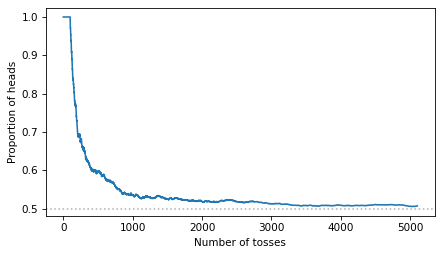

In [9]:
plt.plot(ns, prop_heads)
plt.axhline(0.5, color='0.7', ls=':')
decorate(xlabel='Number of tosses', ylabel='Proportion of heads')

The proportion starts at 1 and declines toward 1/2.
So it might seem like the coin is making up for the early run of heads.
But it's not -- to see why, let's look at the excess, which is the number of heads minus the number we expect from a fair coin, half the number of tosses.

In [10]:
excess = num_heads - ns / 2

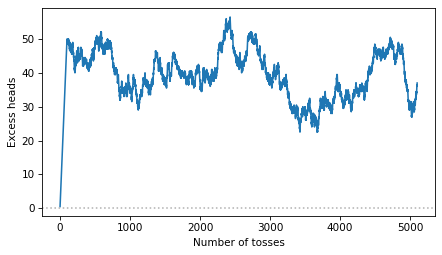

In [11]:
plt.plot(ns, excess)
plt.axhline(0, color='0.7', ls=':')
decorate(xlabel='Number of tosses', ylabel='Excess heads')

During the first 100 tosses, the excess climbs to 50.
After that, it wanders up and down, but it shows no tendency to return to 0.
The coin doesn't compensate for the early heads.

So why does the proportion converge to 1/2?
Because the excess stays about the same while the number of tosses keeps growing.
An excess of 50 heads after 600 tosses makes the proportion about 0.58; after 10,000 tosses, 0.505; after a million tosses, 0.50005.
The early heads are not cancelled out -- they are diluted.

## Discussion

The gambler's fallacy and the law of large numbers don't conflict because they are about different quantities.
The gambler's fallacy is about the next toss: after 100 heads, the probability of heads is still 1/2.
The law of large numbers is about the proportion of heads in the long run, which converges to 1/2.

The apparent conflict comes from assuming that the proportion can only converge if the coin makes up for the early run -- that a surplus of heads has to be canceled by a surplus of tails.
But convergence doesn't require compensation, only dilution.
The surplus doesn't get erased; it becomes negligible compared to the number of tosses.

[*Data Q&A: Answering the real questions with Python*](https://allendowney.github.io/DataQnA/index.html)

Copyright 2024–2026 [Allen B. Downey](https://allendowney.com)

License: [Creative Commons Attribution-NonCommercial-ShareAlike 4.0 International](https://creativecommons.org/licenses/by-nc-sa/4.0/)